In [ ]:
import os
import sys

cwd = os.getcwd()
project_dir = os.path.dirname(cwd)
sys.path.insert(0, project_dir)

In [ ]:
N = 200
ATOL = 0.1
RTOL = 0.1
MIN_PTS_PER_CLUSTER = 100
NUM_INITIAL_CLUSTERS = 2

## Rosenbrock Function 

In [ ]:
import matplotlib.colors as colors
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Circle

from src.adaptive_clustering import adaptive_cluster_algorithm


def rosenbrock_2d(X):
    """
    Compute the 2D Rosenbrock function.
    Given X of shape (n_samples, 2), returns the function values of shape (n_samples, 1).
    """
    x1, x2 = X[:, 0], X[:, 1]
    res = (1 - x1) ** 2 + 100 * (x2 - x1**2) ** 2
    return res[:, np.newaxis]


def grad_rosenbrock_2d(X):
    """
    Compute the gradient of the 2D Rosenbrock function.
    Given X of shape (n_samples, 2), returns the gradient of shape (n_samples, 1, 2).
    """
    x1, x2 = X[:, 0], X[:, 1]
    dfdx1 = -2 * (1 - x1) - 400 * x1 * (x2 - x1**2)
    dfdx2 = 200 * (x2 - x1**2)
    grad = np.vstack([dfdx1, dfdx2]).T
    return grad[:, np.newaxis, :]


x1 = np.linspace(-2, 2, N)
x2 = np.linspace(-1, 3, N)
X1, X2 = np.meshgrid(x1, x2)
X = np.vstack([X1.ravel(), X2.ravel()]).T
Z = rosenbrock_2d(X)

clusters = adaptive_cluster_algorithm(
    X_train=X,
    f=rosenbrock_2d,
    grad_f=grad_rosenbrock_2d,
    cupy_f=None,
    atol=ATOL,
    rtol=RTOL,
    min_pts_per_cluster=MIN_PTS_PER_CLUSTER,
    num_initial_clusters=NUM_INITIAL_CLUSTERS,
)

centroids = np.array([c.centroid for c in clusters])
radii = np.array([float(c.radius) for c in clusters])

/home/prajwal/github-repos/knnsur/src/adaptive_clustering.py:20: UserWarning: CuPy or cuML not available; GPU acceleration will be disabled.
  warnings.warn("CuPy or cuML not available; GPU acceleration will be disabled.")


CUML available: False


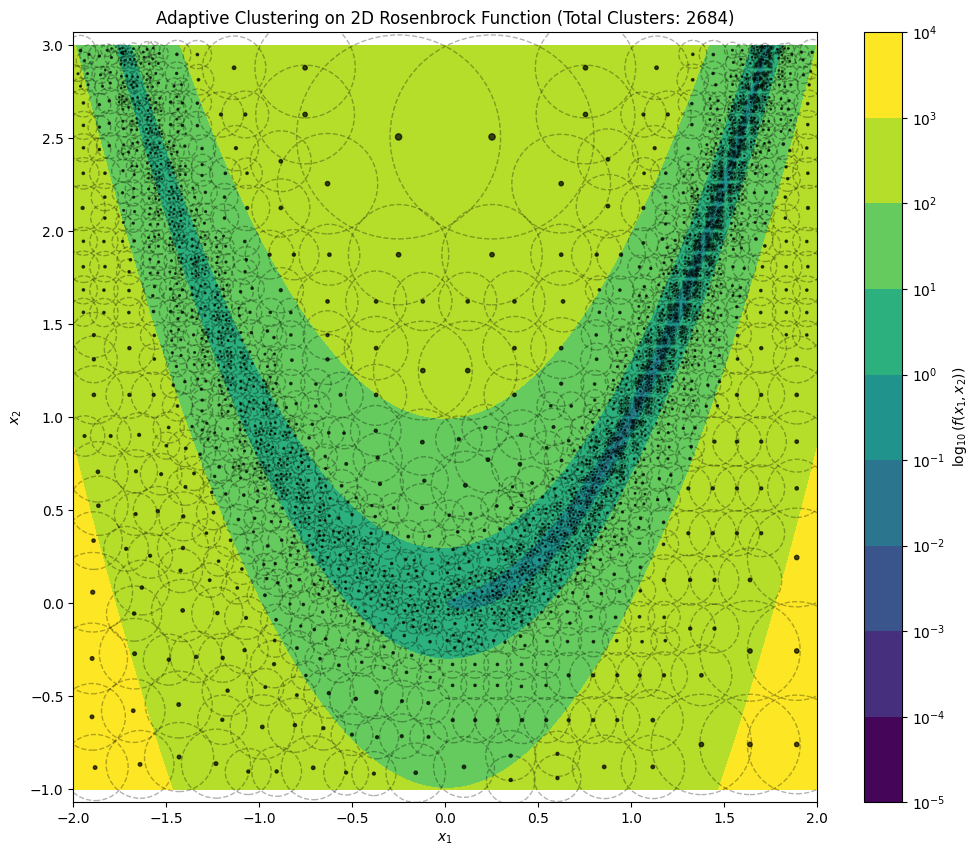

In [ ]:
def plot_adaptive_clustering(
    X1,
    X2,
    Z,
    N,
    centroids,
    radii,
    title: str,
    plot_radii: bool = True,
    s: None | float = None,
    n_levels: int = 30,
    plot_log: bool = True,
):
    plt.figure(figsize=(12, 10))
    if plot_log:
        contour = plt.contourf(
            X1,
            X2,
            Z.reshape(N, N),
            levels=n_levels,
            norm=colors.LogNorm(vmin=Z.min(), vmax=Z.max()),
            cmap="viridis",
        )
        plt.colorbar(contour, label=r"$\log_{10}(f(x_1, x_2))$")
    else:
        contour = plt.contourf(
            X1,
            X2,
            Z.reshape(N, N),
            levels=n_levels,
            cmap="viridis",
        )
        plt.colorbar(contour, label=r"$f(x_1, x_2)$")
    plt.xlabel(r"$x_1$")
    plt.ylabel(r"$x_2$")
    plt.axis("equal")
    plt.title(title)

    # Plot centroids
    normed_radii = (radii - radii.min()) / (radii.max() - radii.min() + 1e-10)
    if not isinstance(s, float):
        s = normed_radii * 20
    plt.scatter(
        centroids[:, 0],
        centroids[:, 1],
        color="k",
        s=s,
        alpha=0.7,
        label="Cluster Centroids",
    )
    if plot_radii:
        # Plot circles representing cluster radii
        for centroid, radius in zip(centroids, radii):
            circle = Circle(
                (centroid[0], centroid[1]),
                radius,
                fill=False,
                linestyle="--",
                alpha=0.3,
            )
            plt.gca().add_artist(circle)


plot_adaptive_clustering(
    X1,
    X2,
    Z,
    N,
    centroids,
    radii,
    f"Adaptive Clustering on 2D Rosenbrock Function (Total Clusters: {len(clusters)})",
)

## Beale Function

In [ ]:
def beale_2d(X):
    """
    Compute the 2D Beale function.
    Given X of shape (n_samples, 2), returns the function values of shape (n_samples, 1).
    """
    x1, x2 = X[:, 0], X[:, 1]
    term1 = (1.5 - x1 + x1 * x2) ** 2
    term2 = (2.25 - x1 + x1 * x2**2) ** 2
    term3 = (2.625 - x1 + x1 * x2**3) ** 2
    res = term1 + term2 + term3
    return res[:, np.newaxis]


def grad_beale_2d(X):
    """
    Compute the gradient of the 2D Beale function.
    Given X of shape (n_samples, 2), returns the gradient of shape (n_samples, 1, 2).
    """
    x1, x2 = X[:, 0], X[:, 1]
    dfdx1 = (
        2 * (1.5 - x1 + x1 * x2) * (-1 + x2)
        + 2 * (2.25 - x1 + x1 * x2**2) * (-1 + x2**2)
        + 2 * (2.625 - x1 + x1 * x2**3) * (-1 + x2**3)
    )
    dfdx2 = (
        2 * (1.5 - x1 + x1 * x2) * (x1)
        + 4 * (2.25 - x1 + x1 * x2**2) * (x1 * x2)
        + 6 * (2.625 - x1 + x1 * x2**3) * (x1 * x2**2)
    )
    grad = np.vstack([dfdx1, dfdx2]).T
    return grad[:, np.newaxis, :]


x1 = np.linspace(-4.5, 4.5, N)
x2 = np.linspace(-4.5, 4.5, N)
X1, X2 = np.meshgrid(x1, x2)
X = np.vstack([X1.ravel(), X2.ravel()]).T
Z = beale_2d(X)

clusters = adaptive_cluster_algorithm(
    X_train=X,
    f=beale_2d,
    grad_f=grad_beale_2d,
    cupy_f=None,
    atol=ATOL,
    rtol=RTOL,
    min_pts_per_cluster=MIN_PTS_PER_CLUSTER,
    num_initial_clusters=NUM_INITIAL_CLUSTERS,
)
centroids = np.array([c.centroid for c in clusters])
radii = np.array([float(c.radius) for c in clusters])

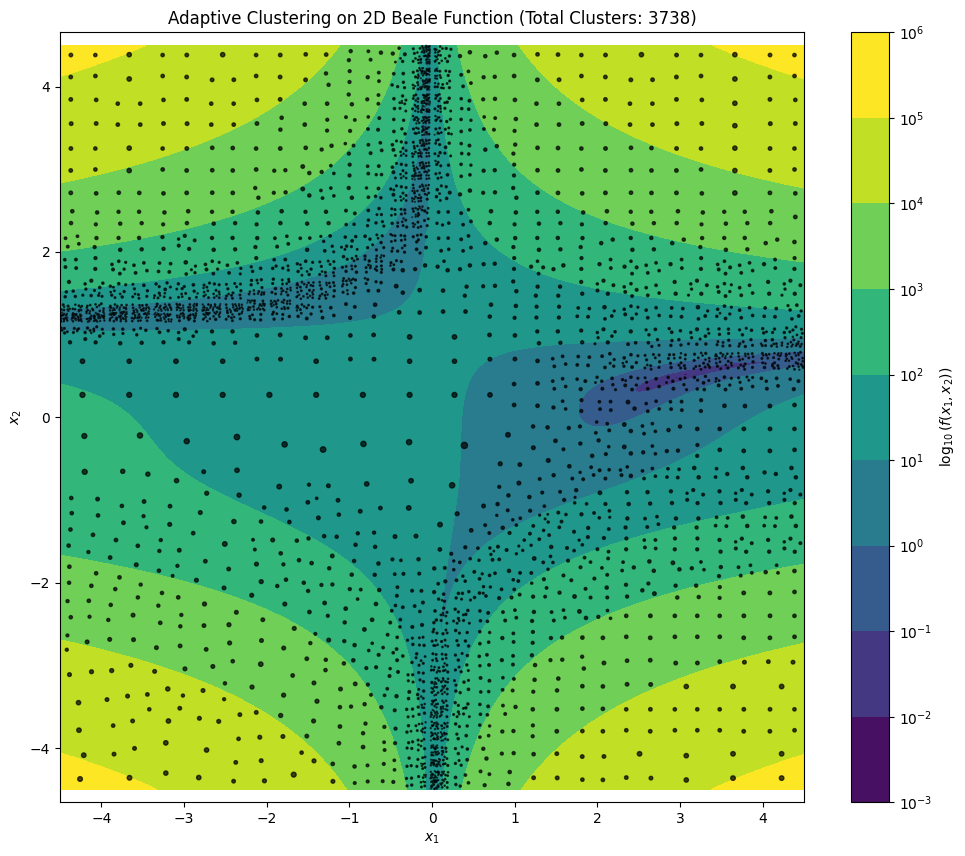

In [ ]:
plot_adaptive_clustering(
    X1,
    X2,
    Z,
    N,
    centroids,
    radii,
    f"Adaptive Clustering on 2D Beale Function (Total Clusters: {len(clusters)})",
    plot_radii=False,
)

## Ackley Function

In [ ]:
def ackley_2d(X):
    """
    Compute the 2D Ackley function.
    Given X of shape (n_samples, 2), returns the function values of shape (n_samples, 1).
    """
    x1, x2 = X[:, 0], X[:, 1]
    term1 = -20 * np.exp(-0.2 * np.sqrt(0.5 * (x1**2 + x2**2)))
    term2 = -np.exp(0.5 * (np.cos(2 * np.pi * x1) + np.cos(2 * np.pi * x2)))
    res = term1 + term2 + 20 + np.e
    return res[:, np.newaxis]


def grad_ackley_2d(X):
    """
    Compute the gradient of the 2D Ackley function.
    Given X of shape (n_samples, 2), returns the gradient of shape (n_samples, 1, 2).
    """
    x1, x2 = X[:, 0], X[:, 1]
    a = 20
    b = 0.2
    c = 2 * np.pi

    sum_sq = x1**2 + x2**2
    term1 = (a * b / np.sqrt(0.5 * sum_sq)) * np.exp(-b * np.sqrt(0.5 * sum_sq))
    dfdx1 = term1 * x1 + (c / 2) * np.sin(c * x1) * np.exp(
        0.5 * (np.cos(c * x1) + np.cos(c * x2))
    )
    dfdx2 = term1 * x2 + (c / 2) * np.sin(c * x2) * np.exp(
        0.5 * (np.cos(c * x1) + np.cos(c * x2))
    )

    grad = np.vstack([dfdx1, dfdx2]).T
    return grad[:, np.newaxis, :]


x1 = np.linspace(-5, 5, N)
x2 = np.linspace(-5, 5, N)
X1, X2 = np.meshgrid(x1, x2)
X = np.vstack([X1.ravel(), X2.ravel()]).T
Z = ackley_2d(X)

clusters = adaptive_cluster_algorithm(
    X_train=X,
    f=ackley_2d,
    grad_f=grad_ackley_2d,
    cupy_f=None,
    atol=ATOL,
    rtol=RTOL,
    min_pts_per_cluster=MIN_PTS_PER_CLUSTER * 3,
    num_initial_clusters=NUM_INITIAL_CLUSTERS,
)
centroids = np.array([c.centroid for c in clusters])
radii = np.array([float(c.radius) for c in clusters])

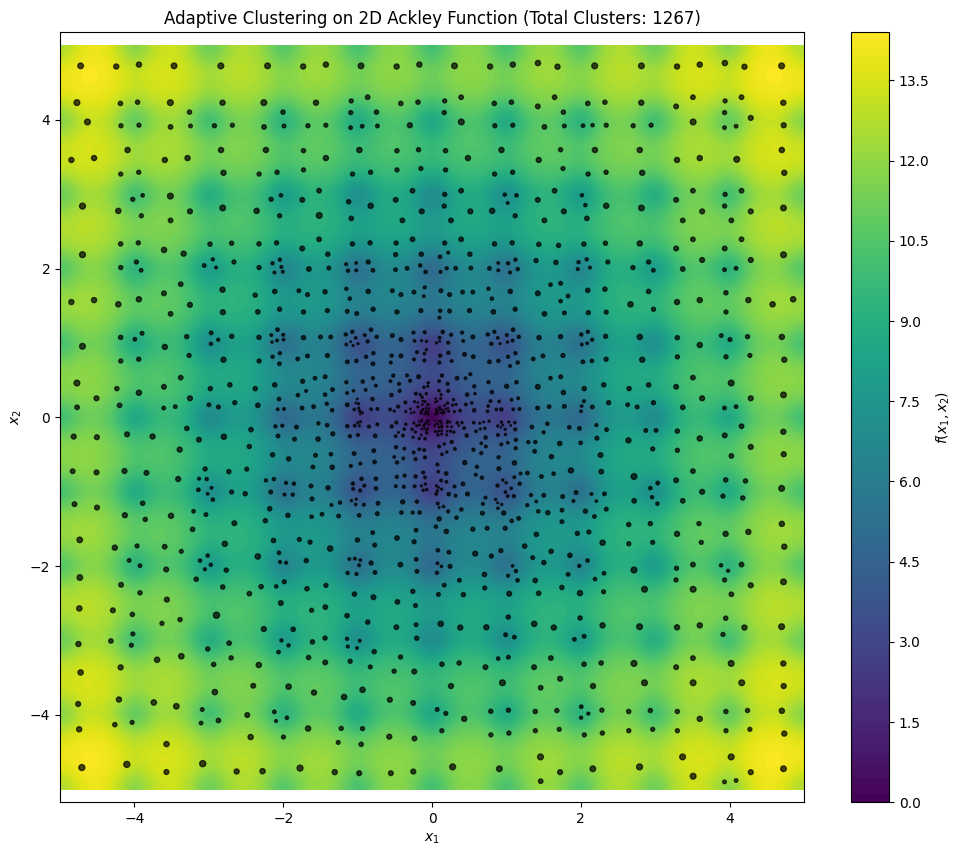

In [ ]:
plot_adaptive_clustering(
    X1,
    X2,
    Z,
    N,
    centroids,
    radii,
    f"Adaptive Clustering on 2D Ackley Function (Total Clusters: {len(clusters)})",
    plot_radii=False,
    plot_log=False,
    n_levels=100,
)

## Goldstein-Price Function

In [ ]:
def goldstein_price_2d(X):
    """
    Compute the 2D Goldstein-Price function.
    Given X of shape (n_samples, 2), returns the function values of shape (n_samples, 1).
    """
    x1, x2 = X[:, 0], X[:, 1]
    term1 = 1 + (x1 + x2 + 1) ** 2 * (
        19 - 14 * x1 + 3 * x1**2 - 14 * x2 + 6 * x1 * x2 + 3 * x2**2
    )
    term2 = 30 + (2 * x1 - 3 * x2) ** 2 * (
        18 - 32 * x1 + 12 * x1**2 + 48 * x2 - 36 * x1 * x2 + 27 * x2**2
    )
    res = term1 * term2
    return res[:, np.newaxis]


def grad_goldstein_price_2d(X):
    """
    Compute the gradient of the 2D Goldstein-Price function.
    Given X of shape (n_samples, 2), returns the gradient of shape (n_samples, 1, 2).
    """
    x1, x2 = X[:, 0], X[:, 1]

    # Partial derivatives
    dfdx1 = (
        2
        * (x1 + x2 + 1)
        * (19 - 14 * x1 + 3 * x1**2 - 14 * x2 + 6 * x1 * x2 + 3 * x2**2)
        + (1 + (x1 + x2 + 1) ** 2) * (-14 + 6 * x1 + 6 * x2)
    ) * (
        30
        + (2 * x1 - 3 * x2) ** 2
        * (18 - 32 * x1 + 12 * x1**2 + 48 * x2 - 36 * x1 * x2 + 27 * x2**2)
    ) + (
        1 + (x1 + x2 + 1) ** 2
    ) * (
        2
        * (2 * x1 - 3 * x2)
        * (18 - 32 * x1 + 12 * x1**2 + 48 * x2 - 36 * x1 * x2 + 27 * x2**2)
        + (2 * x1 - 3 * x2) ** 2 * (-32 + 24 * x1 - 36 * x2)
    )

    dfdx2 = (
        2
        * (x1 + x2 + 1)
        * (19 - 14 * x1 + 3 * x1**2 - 14 * x2 + 6 * x1 * x2 + 3 * x2**2)
        + (1 + (x1 + x2 + 1) ** 2) * (-14 + 6 * x1 + 6 * x2)
    ) * (
        30
        + (2 * x1 - 3 * x2) ** 2
        * (18 - 32 * x1 + 12 * x1**2 + 48 * x2 - 36 * x1 * x2 + 27 * x2**2)
    ) + (
        1 + (x1 + x2 + 1) ** 2
    ) * (
        2
        * (2 * x1 - 3 * x2)
        * (18 - 32 * x1 + 12 * x1**2 + 48 * x2 - 36 * x1 * x2 + 27 * x2**2)
        + (2 * x1 - 3 * x2) ** 2 * (48 - 36 * x1 + 54 * x2)
    )
    grad = np.vstack([dfdx1, dfdx2]).T
    return grad[:, np.newaxis, :]


x1 = np.linspace(-2, 2, N)
x2 = np.linspace(-2, 2, N)
X1, X2 = np.meshgrid(x1, x2)
X = np.vstack([X1.ravel(), X2.ravel()]).T
Z = goldstein_price_2d(X)

clusters = adaptive_cluster_algorithm(
    X_train=X,
    f=goldstein_price_2d,
    grad_f=grad_goldstein_price_2d,
    cupy_f=None,
    atol=ATOL,
    rtol=RTOL,
    min_pts_per_cluster=MIN_PTS_PER_CLUSTER,
    num_initial_clusters=NUM_INITIAL_CLUSTERS,
)
centroids = np.array([c.centroid for c in clusters])
radii = np.array([float(c.radius) for c in clusters])

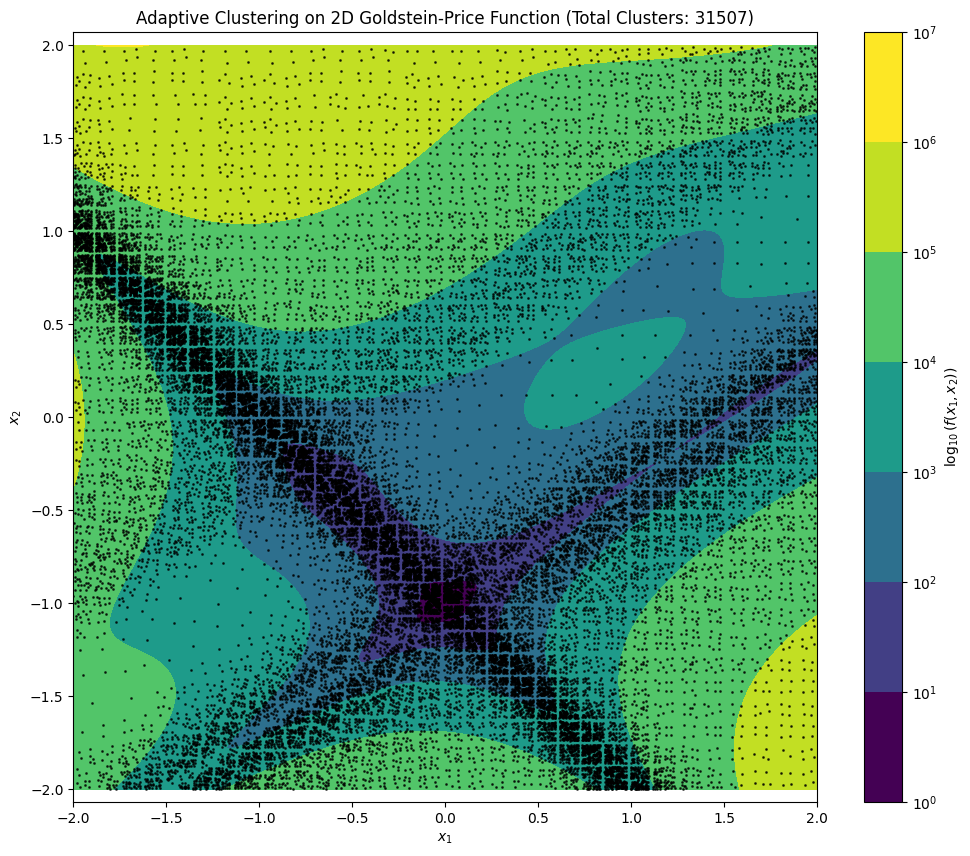

In [ ]:
plot_adaptive_clustering(
    X1,
    X2,
    Z,
    N,
    centroids,
    radii,
    f"Adaptive Clustering on 2D Goldstein-Price Function (Total Clusters: {len(clusters)})",
    plot_radii=False,
    s=1.0,
)

## Himmelblau's Function

In [ ]:
def himmelblau_2d(X):
    """
    Compute the 2D Himmelblau's function.
    Given X of shape (n_samples, 2), returns the function values of shape (n_samples, 1).
    """
    x1, x2 = X[:, 0], X[:, 1]
    term1 = (x1**2 + x2 - 11) ** 2
    term2 = (x1 + x2**2 - 7) ** 2
    res = term1 + term2
    return res[:, np.newaxis]


def grad_himmelblau_2d(X):
    """
    Compute the gradient of the 2D Himmelblau's function.
    Given X of shape (n_samples, 2), returns the gradient of shape (n_samples, 1, 2).
    """
    x1, x2 = X[:, 0], X[:, 1]
    dfdx1 = 4 * (x1**2 + x2 - 11) * x1 + 2 * (x1 + x2**2 - 7)
    dfdx2 = 2 * (x1**2 + x2 - 11) + 4 * (x1 + x2**2 - 7) * x2
    grad = np.vstack([dfdx1, dfdx2]).T
    return grad[:, np.newaxis, :]


x1 = np.linspace(-5, 5, N)
x2 = np.linspace(-5, 5, N)
X1, X2 = np.meshgrid(x1, x2)
X = np.vstack([X1.ravel(), X2.ravel()]).T
Z = himmelblau_2d(X)

clusters = adaptive_cluster_algorithm(
    X_train=X,
    f=himmelblau_2d,
    grad_f=grad_himmelblau_2d,
    cupy_f=None,
    atol=ATOL,
    rtol=RTOL,
    min_pts_per_cluster=MIN_PTS_PER_CLUSTER,
    num_initial_clusters=NUM_INITIAL_CLUSTERS,
)
centroids = np.array([c.centroid for c in clusters])
radii = np.array([float(c.radius) for c in clusters])

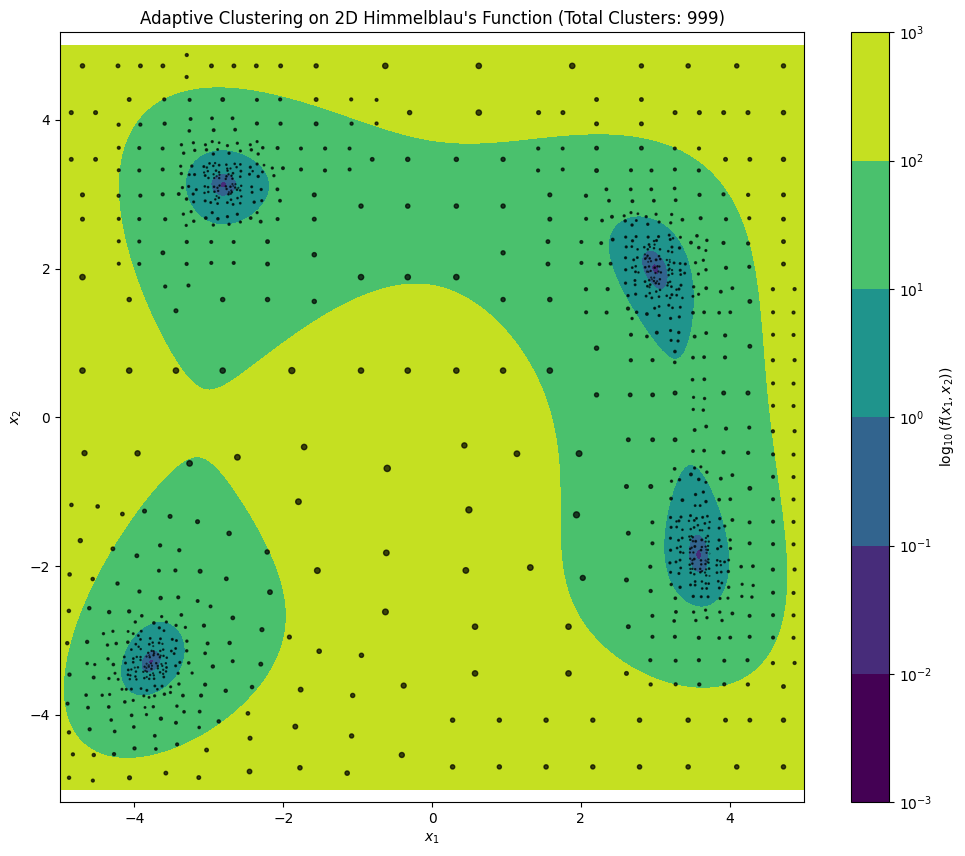

In [ ]:
plot_adaptive_clustering(
    X1,
    X2,
    Z,
    N,
    centroids,
    radii,
    f"Adaptive Clustering on 2D Himmelblau's Function (Total Clusters: {len(clusters)})",
    plot_radii=False,
)

## Rastrigin Function

In [ ]:
def rastrigin_2d(X):
    """
    Compute the 2D Rastrigin function.
    Given X of shape (n_samples, 2), returns the function values of shape (n_samples, 1).
    """
    x1, x2 = X[:, 0], X[:, 1]
    A = 10
    res = (
        A * 2
        + (x1**2 - A * np.cos(2 * np.pi * x1))
        + (x2**2 - A * np.cos(2 * np.pi * x2))
    )
    return res[:, np.newaxis]


def grad_rastrigin_2d(X):
    """
    Compute the gradient of the 2D Rastrigin function.
    Given X of shape (n_samples, 2), returns the gradient of shape (n_samples, 1, 2).
    """
    x1, x2 = X[:, 0], X[:, 1]
    A = 10
    dfdx1 = 2 * x1 + 2 * np.pi * A * np.sin(2 * np.pi * x1)
    dfdx2 = 2 * x2 + 2 * np.pi * A * np.sin(2 * np.pi * x2)
    grad = np.vstack([dfdx1, dfdx2]).T
    return grad[:, np.newaxis, :]


x1 = np.linspace(-5.12, 5.12, N)
x2 = np.linspace(-5.12, 5.12, N)
X1, X2 = np.meshgrid(x1, x2)
X = np.vstack([X1.ravel(), X2.ravel()]).T
Z = rastrigin_2d(X)

clusters = adaptive_cluster_algorithm(
    X_train=X,
    f=rastrigin_2d,
    grad_f=grad_rastrigin_2d,
    cupy_f=None,
    atol=ATOL,
    rtol=RTOL,
    min_pts_per_cluster=MIN_PTS_PER_CLUSTER,
    num_initial_clusters=NUM_INITIAL_CLUSTERS,
)
centroids = np.array([c.centroid for c in clusters])
radii = np.array([float(c.radius) for c in clusters])

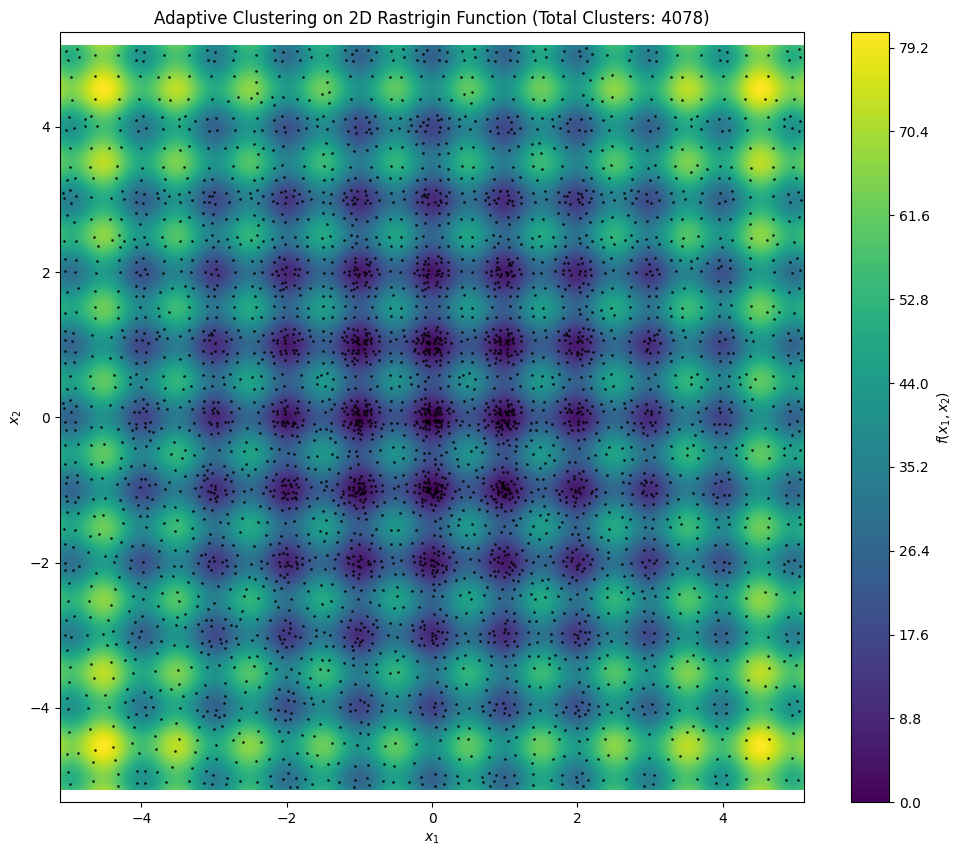

In [15]:
plot_adaptive_clustering(
    X1,
    X2,
    Z,
    N,
    centroids,
    radii,
    f"Adaptive Clustering on 2D Rastrigin Function (Total Clusters: {len(clusters)})",
    plot_radii=False,
    plot_log=False,
    s=1.0,
    n_levels=100,
)